# Week 4: Customer behavior and statistics

**Your job:** calculate a repeat-customer rate, study order values, make four charts, and explain what the results mean. You write the code in the **Your code** cells. Run cells from top to bottom with **Shift+Enter**, then save with **⌘S**.

**Important definitions:** An *order* is a distinct `InvoiceNo`, not an invoice line. A *repeat customer* is an identified customer with **at least two distinct positive-sales invoices** in this dataset. Customers with missing IDs remain in overall revenue but cannot be included in customer-level calculations.

The processed CSV stays local in `data/processed/`. Save charts to `reports/`. The dataset ends on **2011-12-09**, so December 2011 is a partial month.

## 1. Load the cleaned sales data

Run this setup cell first. It reads the Week 2 CSV and treats IDs as text. It also creates the chart folder if needed.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

project_root = next(
    (folder for folder in [Path.cwd().resolve(), *Path.cwd().resolve().parents]
     if (folder / "data" / "processed" / "valid_sales.csv").is_file()),
    None,
)
if project_root is None:
    raise FileNotFoundError("Run Week 2 Section 7 to create data/processed/valid_sales.csv first.")

sales = pd.read_csv(
    project_root / "data" / "processed" / "valid_sales.csv",
    dtype={"InvoiceNo": "string", "StockCode": "string", "CustomerID": "string"},
    parse_dates=["InvoiceDate"],
)
reports_dir = project_root / "reports"
reports_dir.mkdir(exist_ok=True)
print(f"Loaded {len(sales):,} positive-sales lines")
print("Columns:", list(sales.columns))
display(sales.head(3))

Loaded 530,104 positive-sales lines
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country', 'Revenue', 'YearMonth']


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,Revenue,YearMonth
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850,United Kingdom,15.30,2010-12
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850,United Kingdom,20.34,2010-12
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850,United Kingdom,22.00,2010-12


## 2. Build one row per identified customer

You need a new table named `customers` with one row per nonmissing `CustomerID`. Add two columns: `orders` = number of **distinct** `InvoiceNo` values, and `total_spent` = sum of `Revenue`.

**Hints:** Start with `sales.dropna(subset=["CustomerID"])`, then `.groupby("CustomerID").agg(...)`. Inside `agg`, use `orders=("InvoiceNo", "nunique")` and `total_spent=("Revenue", "sum")`. Use `.reset_index()` if you want `CustomerID` as a regular column.

In [2]:
# Your code: create customers and display its first five rows.
customers = (
    sales.dropna(subset=["CustomerID"])
     .groupby("CustomerID")
         .agg(
             orders=("InvoiceNo", "nunique"),
             total_spent=("Revenue", "sum")
         )
         .reset_index()
)

display(customers.head())

,CustomerID,orders,total_spent
0,12346,1,77183.60
1,12347,7,4310.00
2,12348,4,1797.24
3,12349,1,1757.55
4,12350,1,334.40


**Check your result:** Each `CustomerID` should appear once. An invoice with several product lines should count as **one order** for that customer.

In [3]:
# Your check: how many customer rows are there, and are any IDs duplicated?
# Hints: len(customers), customers["CustomerID"].duplicated().sum()
len(customers)


4338

## 3. Calculate the repeat-customer rate

Create a Boolean column `repeat_buyer` that is `True` when `orders >= 2`. Then calculate the percentage of identified customers who are repeat buyers.

**Hint:** The mean of a Boolean column is the fraction of `True` values. Multiply by 100 for a percentage. State the **denominator** in your written answer: identified purchasing customers in this observation period.

In [4]:
# Your code: create repeat_buyer and calculate repeat_rate.
# Hint: customers["repeat_buyer"].mean() * 100
customers["repeat_buyer"] = customers["orders"] >= 2
customers["repeat_buyer"].sum()
display(customers["repeat_buyer"].sum())

repeat_rate = customers["repeat_buyer"].mean() * 100
display(repeat_rate)

np.int64(2845)

np.float64(65.58321807284463)

**My result:** 2,845 of 4,338 identified customers (65.6%) placed at least two distinct positive-sales invoices.

**What this measures:** The share of identified purchasing customers who made more than one order during the observation period.

**What it cannot measure:** Lifetime retention, because purchases before or after this dataset are unknown. Customers without IDs cannot be tracked.

## 4. Study order values

Create `orders`: one row per distinct `InvoiceNo`, with its total `Revenue` as `order_value`. Use `.groupby("InvoiceNo")["Revenue"].sum()` and `.reset_index(name="order_value")`.

Calculate the **mean**, **median**, and **standard deviation** of `order_value`. A high mean relative to the median suggests some large orders pull the average upward. Standard deviation describes variation in order values (pandas uses the sample standard deviation by default).

In [5]:
# Your code: create orders; print the number of orders, mean, median, and standard deviation.
orders = (
    sales.groupby("InvoiceNo")["Revenue"]
    .sum()
    .reset_index(name="order_value")
)

print("Mean:", orders["order_value"].mean())
print("Median:", orders["order_value"].median())
print("Standard deviation:", orders["order_value"].std())


Mean: 534.403033266533
Median: 303.83500000000004
Standard deviation: 1780.48764759875


**My interpretation:** Is the mean higher than the median? What does that suggest about unusually large orders? ___

## 5. Compare single-order and repeat customers fairly

For each identified customer, calculate `average_order_value = total_spent / orders`. Then compare the **median** customer average order value for single-order versus repeat buyers.

Why use average order value? Comparing `total_spent` alone is partly circular: repeat buyers have more orders by definition.

In [6]:
# Your code: add average_order_value to customers.
# Then group by repeat_buyer and calculate the median average_order_value.
customers["average_order_value"] = customers["total_spent"]/customers["orders"]

display(customers.head())


,CustomerID,orders,total_spent,repeat_buyer,average_order_value
0,12346,1,77183.60,False,77183.600000
1,12347,7,4310.00,True,615.714286
2,12348,4,1797.24,True,449.310000
3,12349,1,1757.55,False,1757.550000
4,12350,1,334.40,False,334.400000


**My comparison:** ___

**One caution:** This is an observed association, not proof that becoming a repeat buyer causes a different order value. What else might explain it? ___

## 6. Make four charts

For each chart: write the plotting code, give it a title and axis labels, save it in `reports/`, then display it with `plt.show()`. Start a fresh figure with `fig, ax = plt.subplots(figsize=(10, 5))`. Save with `fig.savefig(reports_dir / "filename.png", dpi=150, bbox_inches="tight")`.

A chart can hide information if its scale or filtering is unclear. Explain any choices such as excluding extreme values **from the view only**. Do not change your underlying calculations just to make a chart look nicer.

### Chart 1 — Monthly positive-sales revenue

Create `monthly` by grouping `sales` on `YearMonth` and summing `Revenue`, then sorting the months. Make a **line chart** with markers. Save as `reports/monthly_revenue.png`.

**Hints:** `monthly = sales.groupby("YearMonth")["Revenue"].sum().sort_index()`; `monthly.plot(ax=ax, marker="o")`; rotate x labels. Label December 2011 as a **partial month** in your interpretation.

YearMonth
2010-12    823746.140
2011-01    691364.560
2011-02    523631.890
2011-03    717639.360
2011-04    537808.621
Name: Revenue, dtype: float64

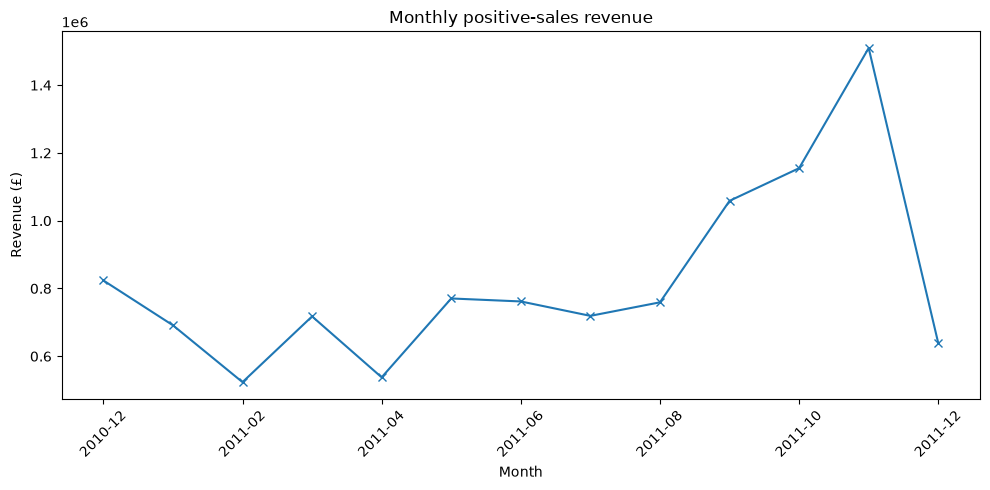

In [7]:
# Your code: monthly line chart, title, labels, save, show.
monthly = (
    sales.groupby("YearMonth")["Revenue"].sum().sort_index()
)
display(monthly.head())

fig, ax = plt.subplots(figsize=(10, 5))
monthly.plot(ax=ax, marker="x")


ax.set_title("Monthly positive-sales revenue")
ax.set_xlabel("Month")
ax.set_ylabel("Revenue (£)")
plt.xticks(rotation=45)
fig.tight_layout()

fig.savefig(reports_dir / "monthly_revenue.png", dpi=150, bbox_inches="tight")
plt.show()

**What the chart shows:** Revenue per month

**Caution about December 2011:** Incomplete data

### Chart 2 — Distribution of order values

Make a **histogram** of `orders["order_value"]`. Save as `reports/order_value_histogram.png`.

**Hints:** `ax.hist(..., bins=30)`; label x as `Order value (£)` and y as `Number of orders`. If a few huge orders squash the rest, display only values up to the 99th percentile **in the chart** and state that choice. Keep all orders in the mean, median, and standard deviation.

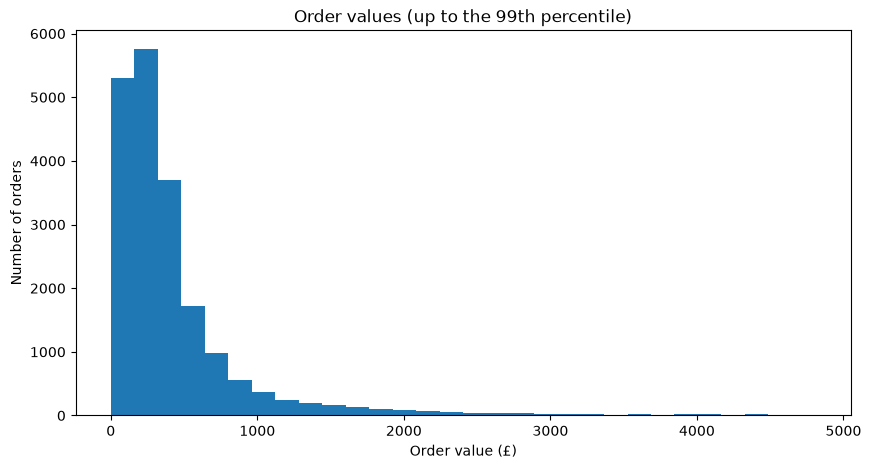

Displayed values up to £4,821.17; 200 orders are outside this chart view.


In [8]:
# Chart 2: show the central 99% of order values so the distribution is readable.
# All orders remain in the Section 4 summary statistics.
order_value = orders["order_value"]
cutoff = order_value.quantile(0.99)
shown_values = order_value[order_value <= cutoff]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(shown_values, bins=30)
ax.set_title("Order values (up to the 99th percentile)")
ax.set_xlabel("Order value (£)")
ax.set_ylabel("Number of orders")
fig.savefig(reports_dir / "order_value_histogram.png", dpi=150, bbox_inches="tight")
plt.show()
print(f"Displayed values up to £{cutoff:,.2f}; {len(order_value) - len(shown_values):,} orders are outside this chart view.")

**Shape and outliers:** The distribution is right-skewed: most orders are relatively small, while a few are much larger.

**Range shown and why:** £0 to about £4,821 (the 99th percentile). The largest 1% of orders are outside this chart view so the typical orders are easier to see; they remain in the summary statistics.

### Chart 3 — Number of orders per identified customer

Make a **histogram** of `customers["orders"]`. Save as `reports/orders_per_customer.png`.

**Hint:** You may focus the x-axis on 1–10 orders if most customers are there. State clearly if customers with more than 10 orders are outside the view; they still remain in the repeat-rate calculation.

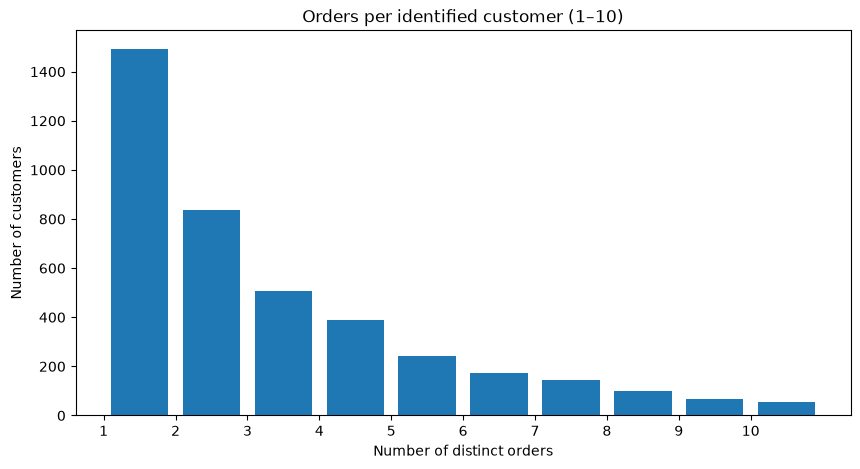

In [9]:
# Your code: orders-per-customer histogram, title, labels, save, show.
visible_orders = customers.loc[customers["orders"] <= 10, "orders"]

fig, ax = plt.subplots(figsize=(10, 5))
ax.hist(visible_orders, bins=range(1, 12), rwidth=0.8)

ax.set_title("Orders per identified customer (1–10)")
ax.set_xlabel("Number of distinct orders")
ax.set_ylabel("Number of customers")
ax.set_xticks(range(1, 11))

fig.savefig(reports_dir / "orders_per_customer.png", dpi=150, bbox_inches="tight")
plt.show()

**What most customers did:** One order was the most common individual order count.

**What the chart may hide:** 337 identified customers had more than 10 orders and are outside this chart view. They still count toward the repeat-customer rate.

### Chart 4 — Typical order value by customer group

Make a **bar chart** comparing the **median customer average order value** for single-order and repeat customers. Save as `reports/median_customer_aov.png`.

**Hints:** Reuse your Section 5 group summary. Label the bars `One order` and `Two or more orders`. This comparison describes the observed customers; it is not a causal experiment.

One order: £257.68; two or more: £303.72


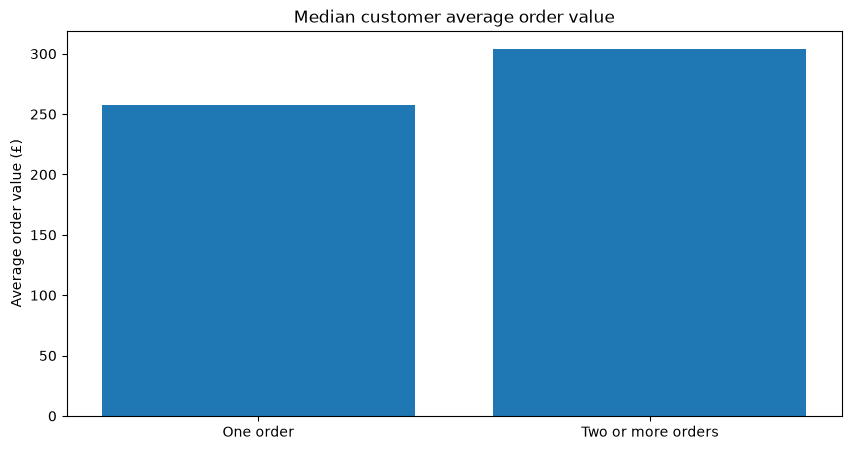

In [10]:
# Chart 4: compare median customer average order values.
customers["average_order_value"] = customers["total_spent"] / customers["orders"]
single_order = customers.loc[customers["orders"] == 1]
repeat_customers = customers.loc[customers["orders"] >= 2]
single_median = single_order["average_order_value"].median()
repeat_median = repeat_customers["average_order_value"].median()
print(f"One order: £{single_median:,.2f}; two or more: £{repeat_median:,.2f}")

fig, ax = plt.subplots(figsize=(10, 5))
ax.bar(["One order", "Two or more orders"], [single_median, repeat_median])
ax.set_title("Median customer average order value")
ax.set_ylabel("Average order value (£)")
fig.savefig(reports_dir / "median_customer_aov.png", dpi=150, bbox_inches="tight")
plt.show()

**My comparison:** ___

**Why this does not prove cause and effect:** ___

## 7. Write a short analyst summary

Write **three findings** with a number and a plain-language meaning. Include a limitation about missing IDs, the short observation period, partial December 2011, or unexamined returns. Your four PNG charts should now be in `reports/`.

When you are done, save the notebook and we can review your analysis before publishing Week 4.

1. **Repeat customers:** 2,845 of 4,338 identified customers (65.6%) placed at least two distinct positive-sales orders during the period. Repeat purchasing was common among customers whose IDs were recorded.
2. **Order values:** The mean order value was £534.40, compared with a median of £303.84. The higher mean suggests that some large orders pull the average upward, so the median better describes a typical order.
3. **Customer groups:** The median customer average order value was £303.72 for repeat customers and £257.68 for single-order customers. Repeat customers had a slightly higher typical order value in this dataset; this comparison does not show that repeat purchasing caused the difference.

**Main limitation:** 132,220 positive-sales lines have no CustomerID, so they contribute to overall sales but cannot be assigned to a customer in the repeat-purchase analysis. Purchases outside the observation period are also unknown.

**One follow-up question for the retailer:** What differs between customers who buy once and those who return, and could those differences help explain repeat purchasing?